# TrustLab — Integrating strategy features into the supervised model

The supervised notebook (`ML_TrustGameProject.ipynb`) predicts a player's move from `round`, `treatment`, `prev_player`, `prev_opp` with Logistic Regression. This notebook keeps **the same data preparation, the same session-based train/test split (random_state=42) and the same model**, and adds:

1. **A baseline check.** Is the model better than the rule "repeat your previous move"?
2. **History features from the unsupervised part**, computed only from rounds *before* the predicted round:
   - `hist_coop_rate`, `hist_coop_last5`: how cooperative the player has been so far
   - `m_defector`, `m_erratic`, `m_forgiving_cooperator`, `m_reciprocator`: K-Means strategy membership of the history so far
   - **strategy × previous-move interactions** (e.g. `m_reciprocator_x_opp_d`): different strategies react differently to the last round
3. **A leak-free evaluation.** The strategy model is refit on the training sessions of every split (never on test players).
4. **The final deployable model** for TrustLab plus a helper that builds its input from a live game.

## 1. Data preparation (same as the supervised notebook)

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4"); warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
DATA, MODELS, FIG = ROOT / "data", ROOT / "models", ROOT / "figures"   # in Colab: put fix.csv/rand.csv in DATA

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from trustlab_unsupervised.integration import (fit_strategy_model_on_sessions, round_history_features,
                                               next_move_features, membership_columns, RATE_FEATURES,
                                               add_strategy_interactions, interaction_columns)
from trustlab_unsupervised.model import StrategyModel

fix = pd.read_csv(DATA / "fix.csv", sep=";")
rand = pd.read_csv(DATA / "rand.csv", sep=";")
columns = ["player", "session", "round", "treatment", "prev_player", "prev_opp", "action_player"]
df = pd.concat([fix[columns], rand[columns]], ignore_index=True)
df["prev_player"] = df["prev_player"].fillna("ND")
df["prev_opp"] = df["prev_opp"].fillna("ND")
df["y"] = df["action_player"].map({"C": 1, "D": 0})

sessions = df[["session", "treatment"]].drop_duplicates()
train_sessions, test_sessions = train_test_split(sessions["session"], test_size=0.25, random_state=42,
                                                 stratify=sessions["treatment"])
train_mask = df["session"].isin(train_sessions)
print("train sessions:", sorted(train_sessions)); print("test sessions: ", sorted(test_sessions))
print("train rows:", train_mask.sum(), "| test rows:", (~train_mask).sum())

train sessions: ['s10n5', 's11n9', 's12n11', 's13n12', 's1m5', 's2m5', 's5m20', 's7m22', 's9n3']
test sessions:  ['s4m8', 's6m22', 's8n3']
train rows: 14000 | test rows: 4800


## 2. Baselines: what does the current model actually learn?

In [2]:
BASE_CAT, BASE_NUM = ["treatment", "prev_player", "prev_opp"], ["round"]

def make_lr(cat, num, C=1.0):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])
    return Pipeline([("preprocessing", pre), ("model", LogisticRegression(C=C, max_iter=2000, random_state=42))])

def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, prob) if len(np.unique(prob)) > 2 else np.nan}

y_test = df.loc[~train_mask, "y"]
repeat_prev = df["prev_player"].map({"C": 1, "D": 0, "ND": 0})   # round 1: predict D (the majority)
base_lr = make_lr(BASE_CAT, BASE_NUM).fit(df.loc[train_mask, BASE_CAT + BASE_NUM], df.loc[train_mask, "y"])
p_base = base_lr.predict_proba(df.loc[~train_mask, BASE_CAT + BASE_NUM])[:, 1]

display(pd.DataFrame({
    "Always predict Defect": scores(y_test, np.zeros(len(y_test))),
    "Repeat own previous move (rule)": scores(y_test, repeat_prev[~train_mask].to_numpy().astype(float)),
    "Logistic Regression (current)": scores(y_test, p_base),
}).T.round(3))

later = (df.loc[~train_mask, "round"] > 1).to_numpy()
same = ((p_base >= .5).astype(int)[later] == repeat_prev[~train_mask].to_numpy()[later]).mean()
print(f"From round 2 on, the current model's prediction equals 'repeat your previous move' in {same:.1%} of test rows.")

,accuracy,precision,recall,f1,roc_auc
Always predict Defect,0.467,0.000,0.000,0.000,NaN
Repeat own previous move (rule),0.838,0.852,0.843,0.848,NaN
Logistic Regression (current),0.838,0.845,0.852,0.849,0.898


From round 2 on, the current model's prediction equals 'repeat your previous move' in 100.0% of test rows.


**Interpretation.** The current Logistic Regression has the same accuracy as the one-line rule *"the player will repeat their previous move"*: its predictions are identical to that rule from round 2 on. Its probabilities still carry more information than the rule (ROC-AUC 0.90), but the hard predictions add nothing yet. This also explains why all five models in the supervised notebook score almost the same: the four features take very few distinct values, so every model learns the same rule. The similar scores are not evidence of a *linear relationship*.

To go beyond "repeat the last move", the model needs to know **who the player is**, meaning how they have played so far. That is exactly what the unsupervised part describes.

## 3. Build history features without leakage

In [3]:
# Strategy model fitted on TRAINING sessions only (the test players are never seen).
sm_train = fit_strategy_model_on_sessions(DATA, train_sessions)
M_COLS = membership_columns(sm_train)
hist = round_history_features(DATA, sm_train)          # features for round t use rounds 1..t-1 only
dfh = df.merge(hist, on=["player", "round"], how="left", validate="one_to_one")
dfh = add_strategy_interactions(dfh, sm_train)
I_COLS = interaction_columns(sm_train)
assert dfh[RATE_FEATURES + M_COLS + I_COLS].notna().all().all()
print("Strategy model trained on", len(set(train_sessions)), "sessions; membership columns:", M_COLS)
dfh.loc[dfh.player == dfh.player.iat[0], ["round", "prev_player", "prev_opp", "action_player"] + RATE_FEATURES + M_COLS].head(8).round(3)

Strategy model trained on 9 sessions; membership columns: ['m_defector', 'm_erratic', 'm_forgiving_cooperator', 'm_reciprocator']


,round,prev_player,prev_opp,action_player,hist_coop_rate,hist_coop_last5,m_defector,m_erratic,m_forgiving_cooperator,m_reciprocator
0,1,ND,ND,D,0.500,0.500,0.250,0.250,0.250,0.250
1,2,D,C,D,0.000,0.000,0.895,0.033,0.037,0.036
2,3,D,D,C,0.000,0.000,0.922,0.030,0.028,0.020
3,4,C,D,D,0.333,0.333,0.234,0.150,0.563,0.052
4,5,D,C,D,0.250,0.250,0.346,0.395,0.165,0.094
5,6,D,C,C,0.200,0.200,0.407,0.409,0.120,0.065
6,7,C,D,D,0.333,0.400,0.164,0.276,0.278,0.282
7,8,D,D,D,0.286,0.400,0.173,0.384,0.125,0.318


## 4. Model comparison

Each feature set is evaluated two ways:
- **Test set**: the supervised notebook's 3 held-out sessions.
- **12-session cross-validation** (4-fold `GroupKFold` by session). In every fold, the strategy model is **refit on that fold's training sessions** before the history features are built, so no fold ever sees its validation players. This estimate is less noisy than one 3-session test set.

In [4]:
FEATURE_SETS = {
    "Current: round, treatment, previous moves": (BASE_CAT, BASE_NUM),
    "+ cooperation history (rates)": (BASE_CAT, BASE_NUM + RATE_FEATURES),
    "+ strategy membership (unsupervised)": (BASE_CAT, BASE_NUM + M_COLS),
    "+ rates + strategy membership": (BASE_CAT, BASE_NUM + RATE_FEATURES + M_COLS),
    "+ rates + strategy + strategy × previous move": (BASE_CAT, BASE_NUM + RATE_FEATURES + M_COLS + I_COLS),
}
FINAL = "+ rates + strategy + strategy × previous move"

# Test-set results (strategy model from the training sessions, built above)
test_rows, probs = {}, {}
for name, (cat, num) in FEATURE_SETS.items():
    m = make_lr(cat, num).fit(dfh.loc[train_mask, cat + num], dfh.loc[train_mask, "y"])
    probs[name] = m.predict_proba(dfh.loc[~train_mask, cat + num])[:, 1]
    test_rows[name] = scores(y_test, probs[name])
test_res = pd.DataFrame(test_rows).T

# 12-session cross-validation with the strategy model refit inside every fold
cv_acc, cv_auc = {n: [] for n in FEATURE_SETS}, {n: [] for n in FEATURE_SETS}
for k, (tr, va) in enumerate(GroupKFold(n_splits=4).split(df, df.y, df.session)):
    fold_train_sessions = df.session.iloc[tr].unique()
    sm_fold = fit_strategy_model_on_sessions(DATA, fold_train_sessions)
    h = round_history_features(DATA, sm_fold)
    d = add_strategy_interactions(df.merge(h, on=["player", "round"], how="left"), sm_fold)
    assert membership_columns(sm_fold) == M_COLS   # same strategy names in every fold
    for name, (cat, num) in FEATURE_SETS.items():
        m = make_lr(cat, num).fit(d.iloc[tr][cat + num], d.iloc[tr]["y"])
        p = m.predict_proba(d.iloc[va][cat + num])[:, 1]
        cv_acc[name].append(accuracy_score(d.iloc[va]["y"], p >= .5)); cv_auc[name].append(roc_auc_score(d.iloc[va]["y"], p))

summary = test_res[["accuracy", "f1", "roc_auc"]].add_prefix("test_")
summary["cv12_accuracy"] = [f"{np.mean(cv_acc[n]):.3f} ± {np.std(cv_acc[n]):.3f}" for n in FEATURE_SETS]
summary["cv12_roc_auc"] = [f"{np.mean(cv_auc[n]):.3f} ± {np.std(cv_auc[n]):.3f}" for n in FEATURE_SETS]
summary.loc["Rule: repeat own previous move"] = [accuracy_score(y_test, repeat_prev[~train_mask]),
                                                  f1_score(y_test, repeat_prev[~train_mask]), np.nan, "", ""]
display(summary.round(3))

,test_accuracy,test_f1,test_roc_auc,cv12_accuracy,cv12_roc_auc
"Current: round, treatment, previous moves",0.838,0.849,0.898,0.829 ± 0.020,0.845 ± 0.065
+ cooperation history (rates),0.853,0.862,0.932,0.838 ± 0.015,0.888 ± 0.040
+ strategy membership (unsupervised),0.849,0.858,0.926,0.837 ± 0.018,0.882 ± 0.043
+ rates + strategy membership,0.851,0.861,0.932,0.839 ± 0.016,0.888 ± 0.040
+ rates + strategy + strategy × previous move,0.857,0.866,0.937,0.842 ± 0.017,0.898 ± 0.035
Rule: repeat own previous move,0.838,0.848,NaN,,


In [5]:
rows = []
for t in ["fix", "rand"]:
    mk = (dfh.loc[~train_mask, "treatment"] == t).to_numpy()
    for name in FEATURE_SETS:
        s = scores(y_test[mk], probs[name][mk]); rows.append({"treatment": t, "model": name, **s})
    rows.append({"treatment": t, "model": "Rule: repeat own previous move",
                 **scores(y_test[mk], repeat_prev[~train_mask].to_numpy()[mk].astype(float))})
display(pd.DataFrame(rows).set_index(["treatment", "model"])[["accuracy", "f1", "roc_auc"]].round(3))

accuracy     f1  \
treatment model                                                            
fix       Current: round, treatment, previous moves         0.863  0.896   
          + cooperation history (rates)                     0.876  0.907   
          + strategy membership (unsupervised)              0.871  0.903   
          + rates + strategy membership                     0.875  0.907   
          + rates + strategy + strategy × previous move     0.886  0.915   
          Rule: repeat own previous move                    0.863  0.896   
rand      Current: round, treatment, previous moves         0.788  0.624   
          + cooperation history (rates)                     0.806  0.632   
          + strategy membership (unsupervised)              0.805  0.635   
          + rates + strategy membership                     0.804  0.629   
          + rates + strategy + strategy × previous move     0.800  0.618   
          Rule: repeat own previous move                    0.789  0.619   

                                                         roc_auc  
treatment model                                                   
fix       Current: round, treatment, previous moves        0.914  
          + cooperation history (rates)                    0.945  
          + strategy membership (unsupervised)             0.937  
          + rates + strategy membership                    0.945  
          + rates + strategy + strategy × previous move    0.950  
          Rule: repeat own previous move                     NaN  
rand      Current: round, treatment, previous moves        0.748  
          + cooperation history (rates)                    0.852  
          + strategy membership (unsupervised)             0.838  
          + rates + strategy membership                    0.852  
          + rates + strategy + strategy × previous move    0.859  
          Rule: repeat own previous move                     NaN

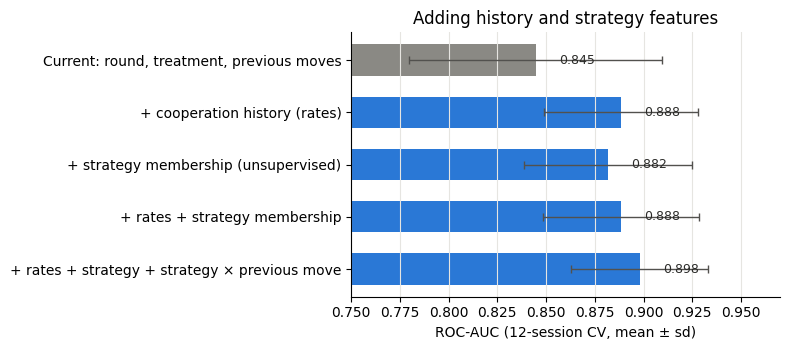

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(FEATURE_SETS)
means = [np.mean(cv_auc[n]) for n in names]; sds = [np.std(cv_auc[n]) for n in names]
ax.barh(range(len(names)), means, xerr=sds, color=["#8a8984"] + ["#2a78d6"] * (len(names) - 1), height=0.6,
        error_kw={"ecolor": "#52514e", "lw": 1, "capsize": 3})
for i, v in enumerate(means): ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9, color="#2b2b29")
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set(xlim=(0.75, 0.97), xlabel="ROC-AUC (12-session CV, mean ± sd)", title="Adding history and strategy features")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e5e1")
plt.tight_layout(); plt.savefig(FIG / "11_integration_auc.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. What the combined model learned (coefficients)

In [7]:
cat, num = FEATURE_SETS[FINAL]
final_eval = make_lr(cat, num).fit(dfh.loc[train_mask, cat + num], dfh.loc[train_mask, "y"])
names_out = final_eval.named_steps["preprocessing"].get_feature_names_out()
coef = pd.Series(final_eval.named_steps["model"].coef_[0], index=[n.split("__")[1] for n in names_out])
coef_df = pd.DataFrame({"coefficient (log-odds of C)": coef, "odds ratio": np.exp(coef)}).sort_values("coefficient (log-odds of C)")
display(coef_df.round(3))

,coefficient (log-odds of C),odds ratio
m_defector_x_own_d,-0.864,0.421
m_reciprocator_x_opp_d,-0.601,0.549
m_erratic,-0.563,0.569
prev_player_D,-0.503,0.605
prev_opp_D,-0.283,0.754
m_forgiving_cooperator_x_own_d,-0.265,0.768
treatment_rand,-0.213,0.808
prev_player_ND,-0.207,0.813
prev_opp_ND,-0.207,0.813
m_forgiving_cooperator_x_opp_d,-0.156,0.855


In [8]:
# Effect of the opponent's defection, by strategy: base coefficient + strategy-specific adjustment
# (log-odds of cooperating when the opponent defected last round, for a player fully in that strategy)
opp_effect = {s: coef["prev_opp_D"] - coef["prev_opp_C"] + coef[f"{s}_x_opp_d"] / dfh.loc[train_mask, f"{s}_x_opp_d"].std()
              for s in M_COLS}
pd.Series(opp_effect, name="log-odds change after opponent defected (approx.)").round(2)

m_defector               -0.46
m_erratic                 0.31
m_forgiving_cooperator   -1.07
m_reciprocator           -3.29
Name: log-odds change after opponent defected (approx.), dtype: float64

Positive coefficients push towards **Cooperate** and negative ones towards **Defect**. Categorical effects are relative to the other levels, and numeric ones are per standard deviation. The membership scores sum to 1, so read them *against each other*.

The interaction terms are where the unsupervised part adds information that cooperation rates cannot: they let the model learn that **each strategy reacts differently to an opponent's defection**. The approximate per-strategy effect is shown in the second table.

## 6. Final model for TrustLab

For deployment, both models are refit on **all 12 sessions**:
- the strategy model (`models/strategy_model.joblib`, the same one the unsupervised notebook saves);
- the next-move Logistic Regression on *round, treatment, previous moves, cooperation history, strategy membership and strategy × previous-move interactions*.

`next_move_features(history, treatment, strategy_model)` turns a live game into the exact input row the Logistic Regression expects.

In [9]:
strategy_model, _ = StrategyModel.fit_from_data(DATA)
hist_all = round_history_features(DATA, strategy_model)
dfa = add_strategy_interactions(df.merge(hist_all, on=["player", "round"], how="left", validate="one_to_one"), strategy_model)
cat, num = FEATURE_SETS[FINAL]
next_move_model = make_lr(cat, num).fit(dfa[cat + num], dfa["y"])

MODELS.mkdir(exist_ok=True)
joblib.dump({"pipeline": next_move_model, "categorical": cat, "numeric": num,
             "note": "Input rows come from trustlab_unsupervised.integration.next_move_features"},
            MODELS / "next_move_lr.joblib")
print("Saved models/next_move_lr.joblib")

def predict_next_move(history, treatment):
    X = next_move_features(history, treatment, strategy_model)
    p_c = float(next_move_model.predict_proba(X[cat + num])[0, 1])
    s = strategy_model.predict_strategy(history) if history else None
    return {"p_cooperate": round(p_c, 3), "prediction": "C" if p_c >= .5 else "D",
            "strategy_so_far": s["strategy"] if s else None}

demo = {
    "new game, fixed partner": ("", "fix"),
    "loyal cooperator, just betrayed (fix)": ("CC," * 15 + "CD", "fix"),
    "habitual defector, opponent cooperated (rand)": ("DD," * 15 + "DC", "rand"),
    "tit-for-tat player, just betrayed (fix)": ("CC,CC,CD,DD,DC,CC,CC,CC,CD,DD,DC,CC,CC,CD", "fix"),
}
pd.DataFrame({k: predict_next_move(*v) for k, v in demo.items()}).T

Saved models/next_move_lr.joblib


,p_cooperate,prediction,strategy_so_far
"new game, fixed partner",0.555,C,None
"loyal cooperator, just betrayed (fix)",0.877,C,Forgiving Cooperator
"habitual defector, opponent cooperated (rand)",0.056,D,Defector
"tit-for-tat player, just betrayed (fix)",0.488,D,Reciprocator
